# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module — Research Assignment**

Name: **Arnav Anand**  |  Roll No: **IMS25037**

This notebook implements **recursive spectral modularity partitioning** on Zachary's Karate Club network. The primary recursion uses Newman's **generalized community modularity matrix**, checks the realised modularity gain before accepting every discrete split, records a full audit log, visualises every iteration, and tracks four node-level metrics.

**Method reference:** M. E. J. Newman (2006), *Modularity and community structure in networks*, PNAS 103(23):8577–8582.

## 1. Setup and data

Zachary's Karate Club graph contains 34 nodes and 78 edges. NetworkX provides the graph and its observed `club` attribute (`'Mr. Hi'` or `'Officer'`), which is used only for evaluating the first split—not for constructing the modularity matrix or detecting communities.


In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib import cm

np.set_printoptions(precision=4, suppress=True)

G = nx.karate_club_graph()          # nodes are 0..33
n, m = G.number_of_nodes(), G.number_of_edges()
nodes = list(G.nodes())             # fixed ordering used for matrix rows/cols
print(f"n = {n} nodes, m = {m} edges")

# Ground truth (the real split of the club)
truth = {v: G.nodes[v]['club'] for v in G}
print("Mr. Hi's group size   :", sum(c == 'Mr. Hi' for c in truth.values()))
print("Officer's group size  :", sum(c == 'Officer' for c in truth.values()))

n = 34 nodes, m = 78 edges
Mr. Hi's group size   : 17
Officer's group size  : 17


## 2. Modularity matrix
$$B = A - \frac{k k^\top}{2m}$$
We build it directly from the adjacency matrix and verify the facts proved in Section 5 of the handout: $B$ is real-symmetric (Prop. 1) and $B\mathbf 1 = 0$ (Prop. 2).

In [2]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # 0/1 adjacency (ignore the 'weight' attr newer NetworkX adds)
k = A.sum(axis=1)                             # degree vector
B = A - np.outer(k, k) / (2 * m)              # modularity matrix

print("B symmetric        :", np.allclose(B, B.T))
print("B @ 1 == 0         :", np.allclose(B @ np.ones(n), 0))
print("Sum of degrees 2m  :", k.sum(), "=", 2 * m)

def modularity_Q(B, labels, m):
    # Q = (1/4m) s^T B s  for a +/-1 vector s (two communities).
    s = np.asarray(labels, dtype=float)
    return s @ B @ s / (4 * m)

# Sanity check: Q of the trivial partition is 0 (Corollary 1)
print("Q(trivial)         :", modularity_Q(B, np.ones(n), m))

B symmetric        : True
B @ 1 == 0         : True
Sum of degrees 2m  : 156.0 = 156
Q(trivial)         : 8.718097469011646e-18


## 3. Spectral bisection of a community

For a current community $C$, the primary method uses Newman's generalized modularity matrix

$$B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il},\qquad i,j\in C.$$

This correction accounts for the fact that vertices in $C$ may have edges to vertices outside $C$. We compute its largest eigenpair with the symmetric eigensolver `numpy.linalg.eigh`, threshold the leading eigenvector at zero, and then **explicitly evaluate the modularity gain of the resulting discrete split**. The sign partition is then refined by deterministic single-node moves: at each step, the node flip with the largest positive increase in the discrete objective is selected, while keeping both sides nonempty. A split is accepted only if its realised gain is positive beyond numerical tolerance. This extra acceptance test prevents a positive relaxed eigenvalue from being mistaken for a guaranteed improvement after thresholding.


In [3]:
TOL = 1e-9
GAIN_TOL = 1e-12

def leading_eigpair(M):
    """Largest eigenpair of a real symmetric matrix, with deterministic sign."""
    vals, vecs = np.linalg.eigh(M)
    lam, u = float(vals[-1]), vecs[:, -1].copy()
    # Eigenvectors are defined only up to sign; fix it for reproducible labels.
    nz = np.flatnonzero(np.abs(u) > TOL)
    if len(nz) and u[nz[0]] < 0:
        u *= -1
    return lam, u

def generalized_modularity_block(B, C):
    """Newman's B^(C), using global B and correcting its diagonal."""
    C = list(C)
    block = B[np.ix_(C, C)].copy()
    block -= np.diag(block.sum(axis=1))
    return block

def bisect_group(B, C, m):
    """
    Attempt one community split.
    Returns (lambda_max, C_plus, C_minus, delta_Q, reason).
    delta_Q is the exact change in the full-graph modularity caused by
    replacing C with the two sign-thresholded children.
    """
    C = list(C)
    if len(C) < 2:
        return 0.0, None, None, 0.0, "singleton community"

    B_C = generalized_modularity_block(B, C)
    lam, u = leading_eigpair(B_C)
    if lam <= TOL:
        return lam, None, None, 0.0, "non-positive leading eigenvalue"

    s = np.where(u > 0.0, 1.0, -1.0)
    if np.all(s == s[0]):
        return lam, None, None, 0.0, "threshold produced an empty side"

    # Improve the discrete sign partition by deterministic single-node
    # Kernighan-Lin-style refinement. At each step, choose the flip that gives
    # the largest positive increase in s^T B^(C) s; never empty either side.
    # This is a discrete post-processing step, not a replacement for the
    # leading-eigenvector spectral proposal.
    refinement_flips = 0
    while True:
        current_score = float(s @ B_C @ s)
        best_gain, best_idx = GAIN_TOL, None
        for j in range(len(s)):
            if np.sum(s == s[j]) <= 1:
                continue  # keep both sides nonempty
            candidate = s.copy()
            candidate[j] *= -1.0
            gain = float(candidate @ B_C @ candidate - current_score)
            if gain > best_gain + GAIN_TOL:
                best_gain, best_idx = gain, j
        if best_idx is None:
            break
        s[best_idx] *= -1.0
        refinement_flips += 1

    Cp = [C[i] for i in range(len(C)) if s[i] > 0]
    Cm = [C[i] for i in range(len(C)) if s[i] < 0]
    # Exact realised change in the full-graph modularity.
    delta_q = float(s @ B_C @ s / (4.0 * m))
    if delta_q <= GAIN_TOL:
        return lam, None, None, delta_q, "refined threshold split has no positive modularity gain"

    return lam, sorted(Cp), sorted(Cm), delta_q, f"accepted; local refinement flips={refinement_flips}"

lam1, Cp, Cm, first_gain, first_reason = bisect_group(B, range(n), m)
print("Leading eigenvalue of generalized B^(V):", round(lam1, 6))
print("Group +1 :", Cp)
print("Group -1 :", Cm)
print("Realised modularity gain ΔQ:", round(first_gain, 6), "|", first_reason)
print("Q after first split:", round(first_gain, 6))


Leading eigenvalue of generalized B^(V): 4.97708
Group +1 : [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 16, 17, 19, 21]
Group -1 : [8, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Realised modularity gain ΔQ: 0.371795 | accepted; local refinement flips=1
Q after first split: 0.371795


### Comparison with the real split
How well does this very first bisection recover the real division of the club?

In [4]:
pred = {v: ('Mr. Hi' if v in Cp else 'Officer') for v in G}
# Group labels are arbitrary, so try both assignments and keep the better
acc = np.mean([pred[v] == truth[v] for v in G])
acc = max(acc, 1 - acc)
flip = np.mean([pred[v] == truth[v] for v in G]) < 0.5   # labels may be swapped
wrong = [v for v in G if (pred[v] == truth[v]) == flip]
print(f"Agreement with ground-truth split: {acc:.1%}  ({int(round(acc*n))}/{n} nodes)")
print("Misclassified node(s):", sorted(wrong))

Agreement with ground-truth split: 94.1%  (32/34 nodes)
Misclassified node(s): [8, 9]


## 4. Recursive bisection with a modularity-gain safeguard

We begin with the entire vertex set. At each round, every currently active community is tested once using its generalized modularity block. Accepted communities are replaced by their two children; rejected communities become terminal and are not tested again. The algorithm stops when a complete round produces no accepted split.

For transparency, the log records the community size, leading eigenvalue, realised $\Delta Q$, and decision reason. Since every accepted split must have $\Delta Q>0$, the global modularity of the partition cannot decrease from one iteration to the next (up to floating-point tolerance).


In [5]:
def recursive_spectral(B, n, m):
    """Recursive generalized spectral partitioning with exact gain checks."""
    communities = [list(range(n))]
    history = [[c[:] for c in communities]]
    log = []
    terminal = set()

    while True:
        new_comms, changed = [], False
        for C in communities:
            key = tuple(sorted(C))
            if key in terminal:
                new_comms.append(C)
                continue

            lam, Cp, Cm, delta_q, reason = bisect_group(B, C, m)
            log.append({
                "iteration": len(history),
                "community": key,
                "size": len(C),
                "lambda_max": lam,
                "delta_Q": delta_q,
                "accepted": Cp is not None,
                "reason": reason,
            })

            if Cp is None:
                terminal.add(key)
                new_comms.append(C)
            else:
                new_comms.extend([Cp, Cm])
                changed = True

        communities = new_comms
        if not changed:
            break
        history.append([c[:] for c in communities])

    return history, log

history, log = recursive_spectral(B, n, m)

print("Recursive split audit log")
for item in log:
    print(
        f"iter {item['iteration']:>2} | size={item['size']:>2} | "
        f"lambda_max={item['lambda_max']:>9.5f} | "
        f"ΔQ={item['delta_Q']:+.7f} | "
        f"{'SPLIT' if item['accepted'] else 'STOP'}: {item['reason']}"
    )

def labels_from_partition(part):
    lab = np.zeros(n, dtype=int)
    for cid, C in enumerate(part):
        lab[C] = cid
    return lab

def total_Q(part):
    """Multi-community modularity from the original global B matrix."""
    return sum(B[np.ix_(C, C)].sum() for C in part) / (2 * m)

print("\\nIteration summary")
q_values = []
for it, part in enumerate(history):
    q = total_Q(part)
    q_values.append(q)
    print(f"iter {it}: {len(part)} communities, sizes {sorted(map(len, part), reverse=True)}, Q={q:.6f}")

assert all(q_values[i+1] >= q_values[i] - 1e-10 for i in range(len(q_values)-1)), "Modularity unexpectedly decreased after an accepted split."
print("PASS: global modularity is non-decreasing across accepted recursive rounds.")


Recursive split audit log
iter  1 | size=34 | lambda_max=  4.97708 | ΔQ=+0.3717949 | SPLIT: accepted; local refinement flips=1
iter  2 | size=17 | lambda_max=  1.17360 | ΔQ=+0.0302433 | SPLIT: accepted; local refinement flips=2
iter  2 | size=17 | lambda_max=  0.80890 | ΔQ=+0.0167653 | SPLIT: accepted; local refinement flips=0
iter  3 | size= 5 | lambda_max=  0.00000 | ΔQ=+0.0000000 | STOP: non-positive leading eigenvalue
iter  3 | size=12 | lambda_max=  0.16375 | ΔQ=-0.0367357 | STOP: refined threshold split has no positive modularity gain
iter  3 | size=11 | lambda_max= -0.00000 | ΔQ=+0.0000000 | STOP: non-positive leading eigenvalue
iter  3 | size= 6 | lambda_max=  0.00000 | ΔQ=+0.0000000 | STOP: non-positive leading eigenvalue
\nIteration summary
iter 0: 1 communities, sizes [34], Q=-0.000000
iter 1: 2 communities, sizes [17, 17], Q=0.371795
iter 2: 4 communities, sizes [12, 11, 6, 5], Q=0.418803
PASS: global modularity is non-decreasing across accepted recursive rounds.


In [6]:
# Cross-check our Q formula against NetworkX's built-in
from networkx.algorithms.community import modularity as nx_modularity
final_part = history[-1]
print("Our Q    :", round(total_Q(final_part), 6))
print("NetworkX :", round(nx_modularity(G, [set(C) for C in final_part], weight=None), 6))

Our Q    : 0.418803
NetworkX : 0.418803


## 5. Visualization after each split
A single **fixed spring layout** (seeded) is reused for every plot so only colours change. Each community gets its own colour and nodes are labelled by ID.

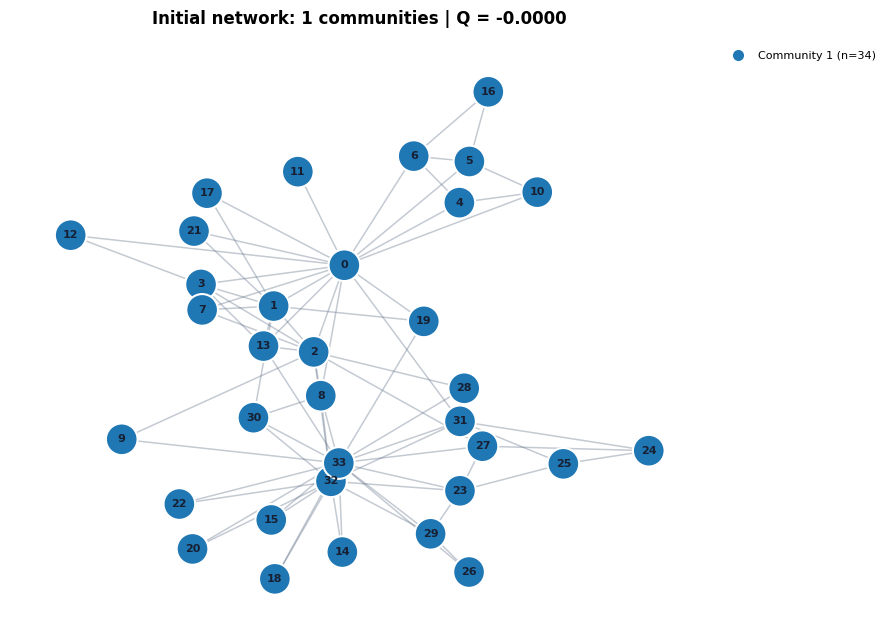

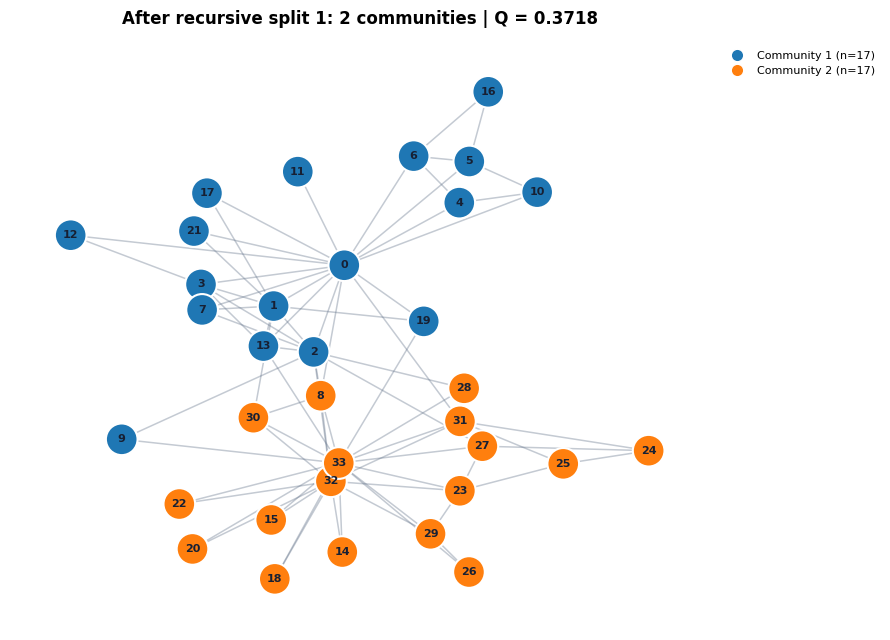

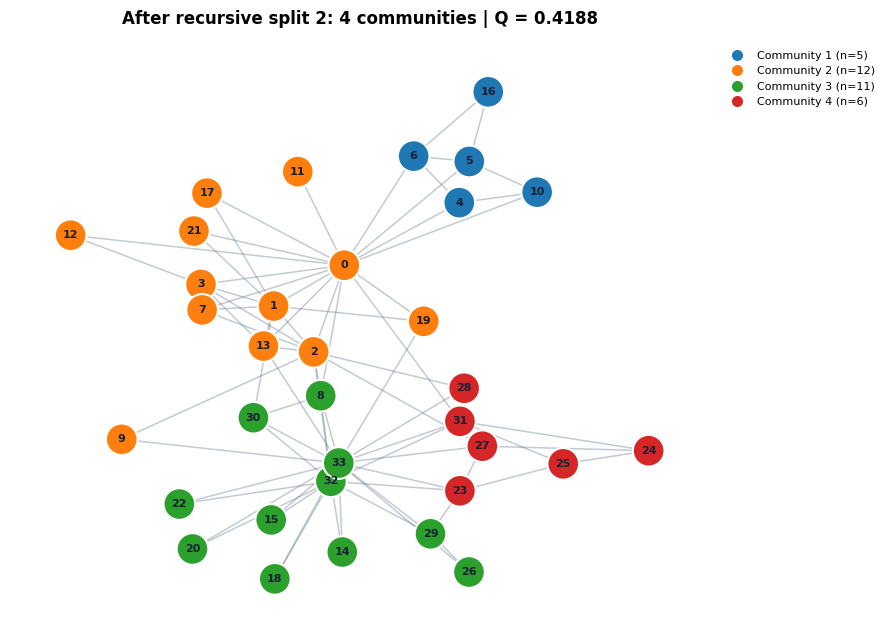

In [7]:
# A fixed layout ensures that only community membership changes between iterations.
pos = nx.spring_layout(G, seed=42, k=0.55, iterations=100)
palette = list(plt.get_cmap("tab10").colors)

def draw_partition(part, title, ax):
    labels = labels_from_partition(part)
    colors = [palette[labels[v] % len(palette)] for v in nodes]

    nx.draw_networkx_edges(
        G, pos, ax=ax, alpha=0.38, width=1.1, edge_color="#64748b"
    )
    nx.draw_networkx_nodes(
        G, pos, ax=ax, node_color=colors, node_size=520,
        edgecolors="white", linewidths=1.5
    )
    nx.draw_networkx_labels(
        G, pos, ax=ax, font_size=8, font_weight="bold",
        font_color="#172033"
    )

    handles = []
    for cid, C in enumerate(part):
        handles.append(
            plt.Line2D(
                [0], [0], marker="o", linestyle="",
                markerfacecolor=palette[cid % len(palette)],
                markeredgecolor="white", markersize=9,
                label=f"Community {cid + 1} (n={len(C)})"
            )
        )
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1),
              frameon=False, fontsize=8)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    ax.axis("off")

for it, part in enumerate(history):
    fig, ax = plt.subplots(figsize=(9, 6.5))
    label = "Initial network" if it == 0 else f"After recursive split {it}"
    draw_partition(part, f"{label}: {len(part)} communities | Q = {total_Q(part):.4f}", ax)
    plt.tight_layout()
    plt.show()


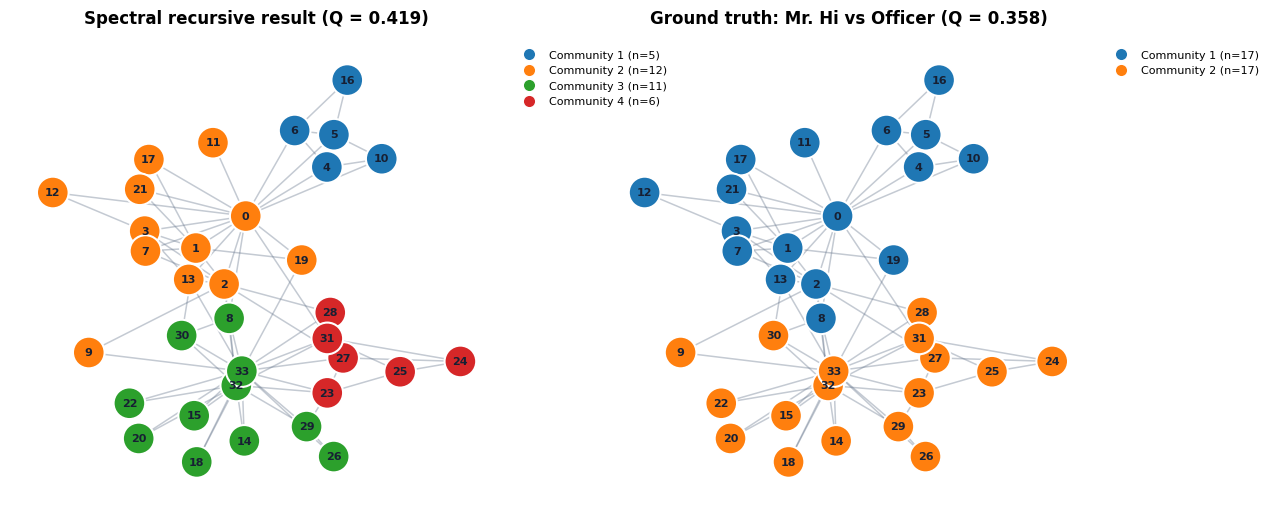

In [8]:
# Final partition vs. the real club split, side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
draw_partition(history[-1], f"Spectral recursive result (Q = {total_Q(history[-1]):.3f})", axes[0])
real = [[v for v in G if truth[v] == 'Mr. Hi'], [v for v in G if truth[v] == 'Officer']]
draw_partition(real, f"Ground truth: Mr. Hi vs Officer (Q = {total_Q(real):.3f})", axes[1])
plt.show()

## 6. Node metrics after each split
The four metrics are computed with NetworkX built-ins (`degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`).

**Design choice.** If the metrics are computed on the full graph $G$, they never change, because splitting only relabels nodes. To capture how community structure affects them, after each split we compute every metric **inside each node's own community**, i.e. on the induced subgraph $G[C]$ containing that node. Iteration 0 is the whole graph, so it equals the usual global metrics. Within a community, closeness is computed on that subgraph (NetworkX's Wasserman–Faust normalisation handles disconnected pieces), and a singleton community gets 0 for every metric.

In [9]:
metric_funcs = {
    'Degree centrality':      nx.degree_centrality,
    'Betweenness centrality': nx.betweenness_centrality,
    'Closeness centrality':   nx.closeness_centrality,
    'Clustering coefficient': nx.clustering,
}

def metrics_for_partition(part):
    # Each metric is computed on the subgraph induced by the node's community.
    out = {name: {} for name in metric_funcs}
    for C in part:
        H = G.subgraph(C)
        for name, f in metric_funcs.items():
            vals = f(H) if H.number_of_nodes() > 1 else {v: 0.0 for v in C}
            for v in C:
                out[name][v] = vals[v]
    return out

# dictionary keyed by iteration number, as required
metrics_by_iter = {it: metrics_for_partition(part) for it, part in enumerate(history)}

# Quick check: iteration 0 should match the global NetworkX values
assert all(np.isclose(metrics_by_iter[0]['Betweenness centrality'][v], nx.betweenness_centrality(G)[v]) for v in G)
print("Iterations stored:", list(metrics_by_iter.keys()))
print("Metrics stored   :", list(metrics_by_iter[0].keys()))

Iterations stored: [0, 1, 2]
Metrics stored   : ['Degree centrality', 'Betweenness centrality', 'Closeness centrality', 'Clustering coefficient']


In [10]:
import pandas as pd
rows = []
for it, md_ in metrics_by_iter.items():
    for name, d in md_.items():
        for v, val in d.items():
            rows.append((it, name, v, val))
df = pd.DataFrame(rows, columns=['iteration', 'metric', 'node', 'value'])
wide = df.pivot_table(index='node', columns=['metric', 'iteration'], values='value')
wide.round(3).head(10)

metric    Betweenness centrality                ... Degree centrality              
iteration                      0      1      2  ...                 0      1      2
node                                            ...                                
0                          0.438  0.670  0.450  ...             0.485  0.875  0.909
1                          0.054  0.077  0.168  ...             0.273  0.500  0.727
2                          0.144  0.127  0.186  ...             0.303  0.375  0.545
3                          0.012  0.023  0.050  ...             0.182  0.375  0.545
4                          0.001  0.003  0.083  ...             0.091  0.188  0.500
5                          0.030  0.061  0.250  ...             0.121  0.250  0.750
6                          0.030  0.061  0.250  ...             0.121  0.250  0.750
7                          0.000  0.000  0.000  ...             0.121  0.250  0.364
8                          0.056  0.000  0.000  ...             0.152  0.188  0.300
9                          0.001  0.000  0.000  ...             0.061  0.062  0.091

[10 rows x 12 columns]

## 7. Evolution of each metric across iterations
One line per node (all 34), with the 5 nodes of highest global value highlighted and legended; others are grey so trends remain readable.

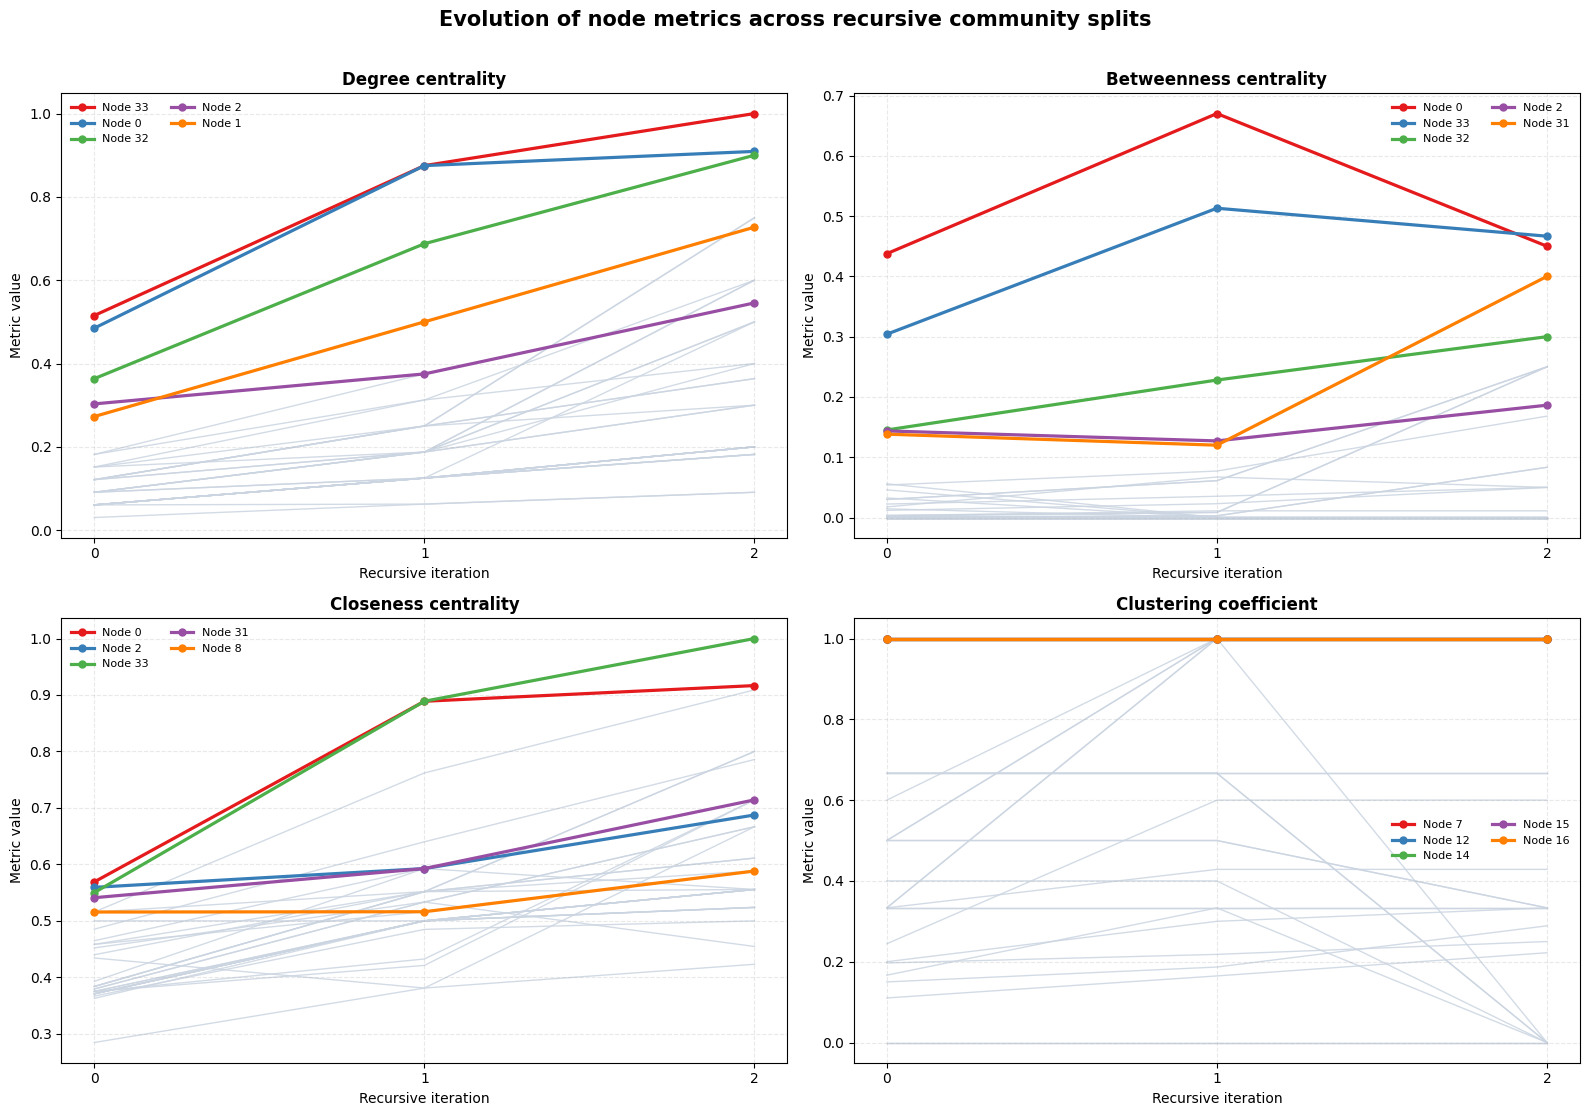

In [11]:
# Every node is shown. The five strongest nodes at iteration 0 are highlighted.
iters = sorted(metrics_by_iter)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
highlight_colors = plt.get_cmap("Set1").colors

for ax, name in zip(axes.ravel(), metric_funcs):
    series = {v: [metrics_by_iter[it][name][v] for it in iters] for v in nodes}
    top = sorted(nodes, key=lambda v: series[v][0], reverse=True)[:5]

    # All 34 nodes remain visible as thin, muted lines.
    for v in nodes:
        if v not in top:
            ax.plot(iters, series[v], color="#cbd5e1", linewidth=1.0,
                    alpha=0.85, zorder=1)

    # Highlight the top five baseline nodes.
    for j, v in enumerate(top):
        ax.plot(iters, series[v], marker="o", markersize=5,
                linewidth=2.3, color=highlight_colors[j],
                label=f"Node {v}", zorder=3)

    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Recursive iteration")
    ax.set_ylabel("Metric value")
    ax.set_xticks(iters)
    ax.grid(True, linestyle="--", alpha=0.28)
    ax.legend(fontsize=8, ncol=2, frameon=False)

fig.suptitle("Evolution of node metrics across recursive community splits",
             fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()


### Reading the metric plots

The line charts display all 34 nodes: the five nodes with the highest baseline value are highlighted, while the remaining nodes are shown in muted grey to preserve readability. The heatmaps complement the line charts by displaying every node's value at every iteration. The final mean-trend chart summarizes the average change across the network.

Metrics are evaluated on each node's own induced community at each iteration. Consequently, these plots describe within-community centrality and cohesion, rather than changes to the original full graph.

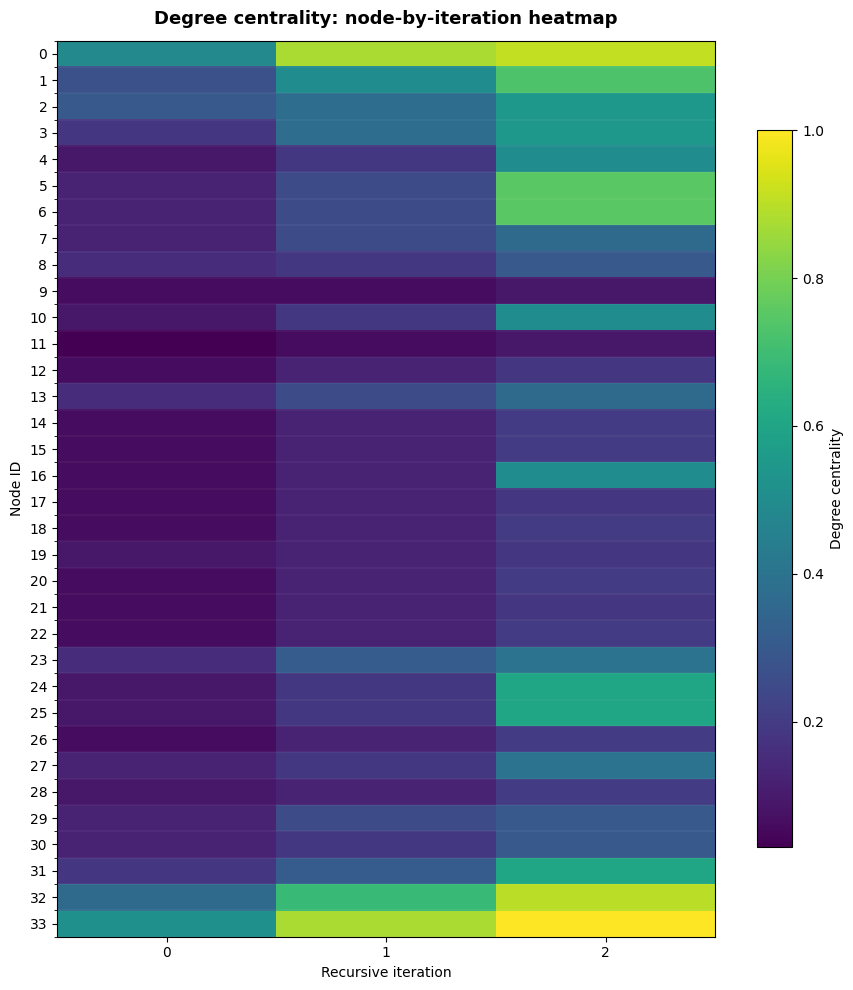

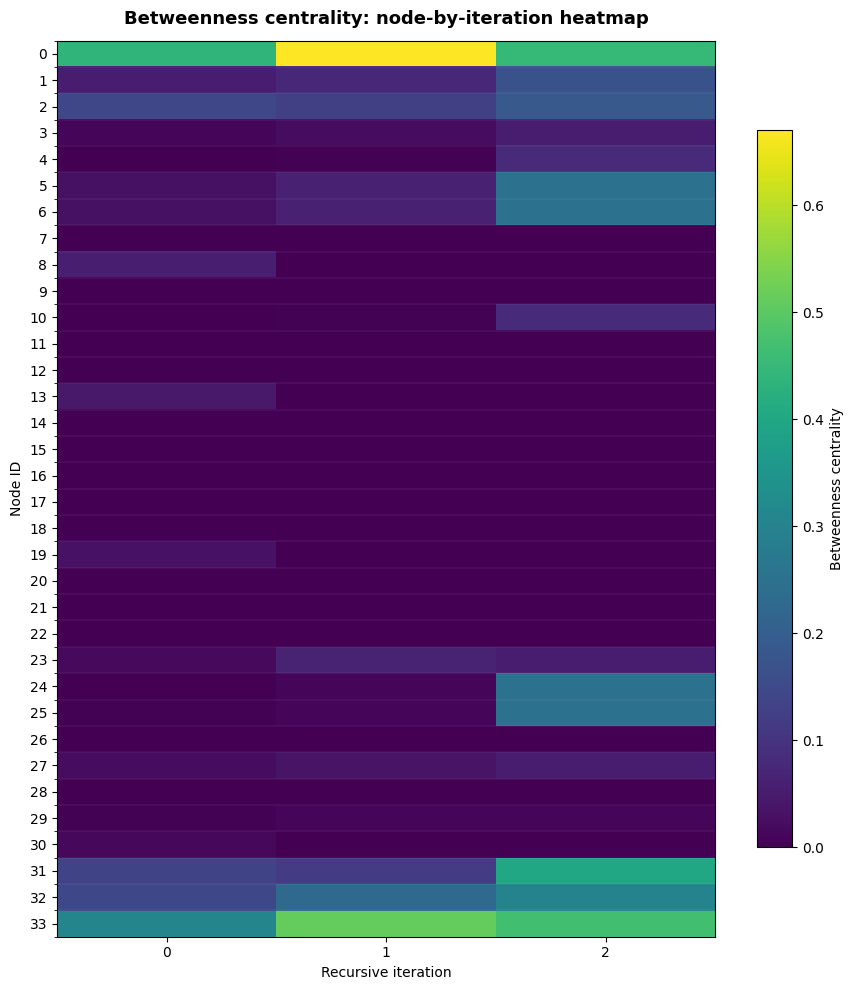

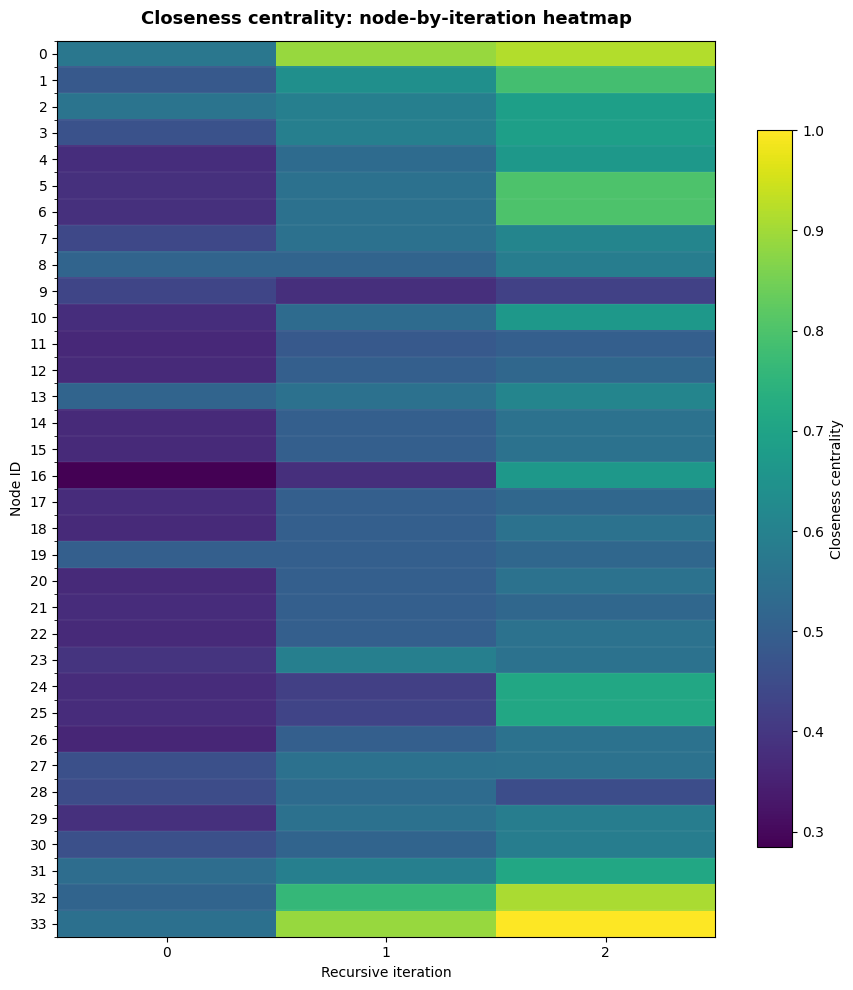

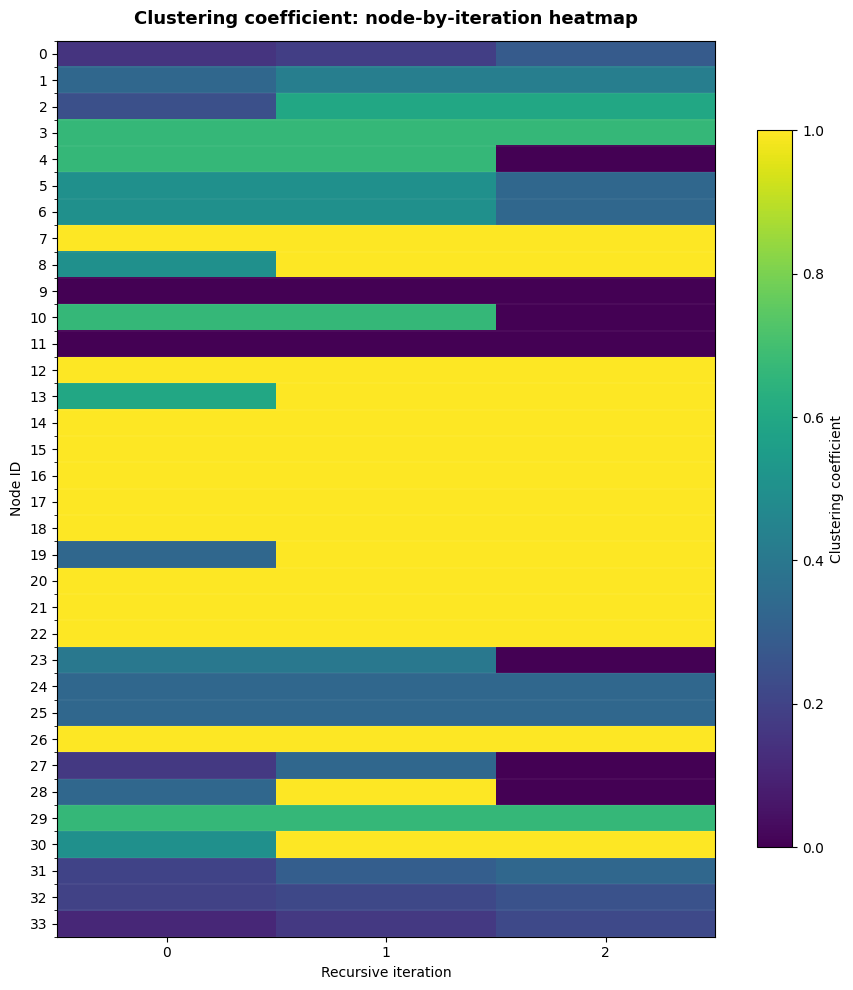

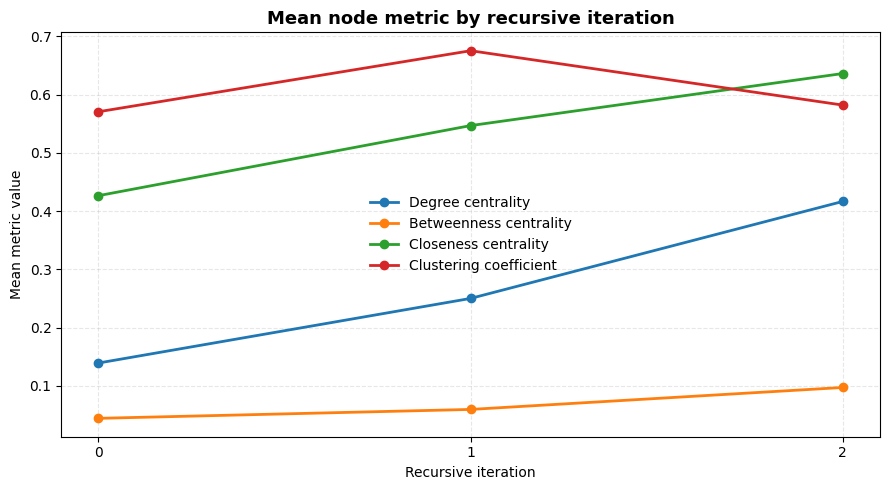

In [12]:
# Heatmaps show all 34 nodes at once without overcrowded line-chart legends.
for name in metric_funcs:
    matrix = np.array([
        [metrics_by_iter[it][name][v] for it in iters]
        for v in nodes
    ])
    fig, ax = plt.subplots(figsize=(9, 10))
    im = ax.imshow(matrix, aspect="auto", cmap="viridis", interpolation="nearest")
    ax.set_title(f"{name}: node-by-iteration heatmap",
                 fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("Recursive iteration")
    ax.set_ylabel("Node ID")
    ax.set_xticks(range(len(iters)), labels=iters)
    ax.set_yticks(range(len(nodes)), labels=nodes)
    ax.set_yticks(np.arange(-0.5, len(nodes), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.25, alpha=0.25)
    fig.colorbar(im, ax=ax, label=name, shrink=0.8)
    fig.tight_layout()
    plt.show()

# Mean metric values provide a compact view of the overall trend.
mean_metrics = {
    name: [np.mean([metrics_by_iter[it][name][v] for v in nodes]) for it in iters]
    for name in metric_funcs
}
fig, ax = plt.subplots(figsize=(9, 5))
for name, values in mean_metrics.items():
    ax.plot(iters, values, marker="o", linewidth=2, label=name)
ax.set_title("Mean node metric by recursive iteration",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Recursive iteration")
ax.set_ylabel("Mean metric value")
ax.set_xticks(iters)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## 8. Supporting numbers for the discussion

In [13]:
# Rank of every node in each metric at each iteration; which nodes stay in the top 5?
from collections import Counter
for name in metric_funcs:
    cnt = Counter()
    for it in iters:
        top5 = sorted(nodes, key=lambda v: metrics_by_iter[it][name][v], reverse=True)[:5]
        cnt.update(top5)
    consistent = sorted([v for v, c in cnt.items() if c == len(iters)])
    print(f"{name:24s} | in top-5 at ALL {len(iters)} iterations: {consistent}")

print("\nGlobal top-5 by each metric (iteration 0):")
for name in metric_funcs:
    top5 = sorted(nodes, key=lambda v: metrics_by_iter[0][name][v], reverse=True)[:5]
    print(f"  {name:24s}: {top5}")

# Mean metric value per iteration
print("\nMean value per iteration")
print(df.groupby(['metric', 'iteration'])['value'].mean().unstack().round(3))

Degree centrality        | in top-5 at ALL 3 iterations: [0, 32, 33]
Betweenness centrality   | in top-5 at ALL 3 iterations: [0, 31, 32, 33]
Closeness centrality     | in top-5 at ALL 3 iterations: [0, 33]
Clustering coefficient   | in top-5 at ALL 3 iterations: [7, 12, 14]

Global top-5 by each metric (iteration 0):
  Degree centrality       : [33, 0, 32, 2, 1]
  Betweenness centrality  : [0, 33, 32, 2, 31]
  Closeness centrality    : [0, 2, 33, 31, 8]
  Clustering coefficient  : [7, 12, 14, 15, 16]

Mean value per iteration
iteration                   0      1      2
metric                                     
Betweenness centrality  0.044  0.059  0.097
Closeness centrality    0.426  0.547  0.636
Clustering coefficient  0.571  0.675  0.582
Degree centrality       0.139  0.250  0.417


## 9. Method comparison: handout block vs. generalized block

The assignment introduces the plain restricted block $B[C,C]$. Newman's generalized block adds a diagonal correction that accounts for links from a candidate community to the rest of the graph. Both variants are implemented below and compared using the same graph and the same discrete sign-thresholding rule.

The generalized version is used for the main results above because it is the appropriate modularity matrix for recursively splitting a sub-community. The plain-block version is retained as a transparent baseline, rather than silently treating the two formulations as identical.


In [14]:
def bisect_group_plain(B, C):
    """Assignment-style baseline: use the uncorrected restricted block B[C,C]."""
    C = list(C)
    if len(C) < 2:
        return None, None
    block = B[np.ix_(C, C)]
    lam, u = leading_eigpair(block)
    if lam <= TOL:
        return None, None
    s = np.where(u > 0.0, 1.0, -1.0)
    Cp = [C[i] for i in range(len(C)) if s[i] > 0]
    Cm = [C[i] for i in range(len(C)) if s[i] < 0]
    if not Cp or not Cm:
        return None, None
    return sorted(Cp), sorted(Cm)

def recursive_plain(B, n):
    communities = [list(range(n))]
    while True:
        updated, changed = [], False
        for C in communities:
            Cp, Cm = bisect_group_plain(B, C)
            if Cp is None:
                updated.append(C)
            else:
                updated.extend([Cp, Cm])
                changed = True
        communities = updated
        if not changed:
            return communities

plain_final = recursive_plain(B, n)
generalized_final = history[-1]
plain_q = total_Q(plain_final)
generalized_q = total_Q(generalized_final)

print("COMPARISON OF RECURSIVE FORMULATIONS")
print(f"Plain restricted block : {len(plain_final)} communities | Q = {plain_q:.6f}")
print(f"Generalized block      : {len(generalized_final)} communities | Q = {generalized_q:.6f}")
print("Plain community sizes  :", sorted(map(len, plain_final), reverse=True))
print("Generalized sizes      :", sorted(map(len, generalized_final), reverse=True))
print("Main algorithm selected: generalized block with a positive realised-ΔQ acceptance test.")

# Confirm the reported final Q against NetworkX for the selected primary method.
q_nx = nx.community.modularity(G, [set(C) for C in generalized_final], weight=None)
print(f"NetworkX cross-check   : Q = {q_nx:.6f}")
assert np.isclose(generalized_q, q_nx, atol=1e-10)


COMPARISON OF RECURSIVE FORMULATIONS
Plain restricted block : 5 communities | Q = 0.409435
Generalized block      : 4 communities | Q = 0.418803
Plain community sizes  : [13, 10, 5, 5, 1]
Generalized sizes      : [12, 11, 6, 5]
Main algorithm selected: generalized block with a positive realised-ΔQ acceptance test.
NetworkX cross-check   : Q = 0.418803


## 10. Discussion

### 1. Nodes That Stay Central Across Splits

The initial spectral split is compared with the observed Mr. Hi / Officer division in Section 3. The recursive analysis then asks a different question: how does the graph subdivide when each emerging community is tested again? Node centrality is not synonymous with community membership. A node may be globally central because it connects factions, yet become less central when metrics are recomputed only inside its own final community.

The ranking table in Section 8 identifies which nodes remain prominent under each metric. In interpreting these rankings, degree highlights local connectivity, betweenness highlights shortest-path brokerage, closeness captures reachability, and clustering measures local triangle density.

### 2. Why the Generalized Matrix Matters

For a community $C$, simply taking the principal block $B[C,C]$ does not account for the contribution of edges from nodes in $C$ to nodes outside $C$ when evaluating a further split. The generalized matrix

$$B^{(C)}=B[C,C]-\operatorname{diag}\left(\sum_{j\in C}B_{ij}\right)$$

incorporates this boundary effect. This is why the generalized matrix is used in the primary recursion, while the plain restricted block is retained as a baseline comparison in Section 9.

A second safeguard is important: a positive leading eigenvalue describes the relaxed real-valued optimization problem. After thresholding the eigenvector to $+1/-1$, the resulting discrete split is not automatically guaranteed to improve modularity. The implementation therefore computes the realised global modularity change $\Delta Q$ and accepts a split only when $\Delta Q$ is positive beyond numerical tolerance. The audit log makes every accepted and rejected split inspectable.

### 3. How Community Splits Affect the Metrics

All four metrics are recomputed on each node's induced community subgraph. Thus, the values describe a node's position *within its current community*, not its position in the unchanged full graph. Smaller communities change the normalization of degree and closeness and can remove cross-community shortest paths that previously contributed to betweenness. Clustering measures the density of links among a node's neighbours and may change as the induced subgraph removes external neighbours.

These values should not be interpreted as the whole network physically gaining connectivity. They reflect a change in the graph on which each metric is evaluated.

### 4. Final Community-Level Metrics

The table below reports the four metrics for every node in the final partition produced by the primary generalized recursive algorithm. Each value is calculated on the induced subgraph corresponding to that node's final community. A singleton community has zero for all four metrics.


In [15]:
final_it = max(metrics_by_iter)
final_metrics = metrics_by_iter[final_it]

print(f"FINAL COMMUNITY-LEVEL METRICS (ITERATION {final_it})")
print("Metrics are computed inside each node's final induced community.\n")
print(f"{'Node':<6} | {'Degree':<10} | {'Betweenness':<13} | {'Closeness':<11} | {'Clustering':<10}")
print("-" * 68)

for node_id in sorted(G.nodes()):
    deg = final_metrics['Degree centrality'][node_id]
    bet = final_metrics['Betweenness centrality'][node_id]
    clo = final_metrics['Closeness centrality'][node_id]
    clu = final_metrics['Clustering coefficient'][node_id]
    print(f"{node_id:<6} | {deg:<10.4f} | {bet:<13.4f} | {clo:<11.4f} | {clu:<10.4f}")


FINAL COMMUNITY-LEVEL METRICS (ITERATION 2)
Metrics are computed inside each node's final induced community.

Node   | Degree     | Betweenness   | Closeness   | Clustering
--------------------------------------------------------------------
0      | 0.9091     | 0.4500        | 0.9167      | 0.2889    
1      | 0.7273     | 0.1682        | 0.7857      | 0.4286    
2      | 0.5455     | 0.1864        | 0.6875      | 0.6000    
3      | 0.5455     | 0.0500        | 0.6875      | 0.6667    
4      | 0.5000     | 0.0833        | 0.6667      | 0.0000    
5      | 0.7500     | 0.2500        | 0.8000      | 0.3333    
6      | 0.7500     | 0.2500        | 0.8000      | 0.3333    
7      | 0.3636     | 0.0000        | 0.6111      | 1.0000    
8      | 0.3000     | 0.0000        | 0.5882      | 1.0000    
9      | 0.0909     | 0.0000        | 0.4231      | 0.0000    
10     | 0.5000     | 0.0833        | 0.6667      | 0.0000    
11     | 0.0909     | 0.0000        | 0.5000      | 0.0000    
12

## 11. References

1. Newman, M. E. J. (2006). “Modularity and community structure in networks.” *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103
2. Zachary, W. W. (1977). “An Information Flow Model for Conflict and Fission in Small Groups.” *Journal of Anthropological Research*, 33(4), 452–473.
3. NetworkX documentation. “Karate Club Graph” and documentation for degree centrality, betweenness centrality, closeness centrality, and clustering. https://networkx.org/documentation/stable/
4. Implementation and visualizations: code written and adapted for this assignment using NumPy, NetworkX, Matplotlib, and pandas.
